# 01 — Data Understanding (Stage 1)
**AI-Based Sales Forecasting and Inventory Optimization System**

Goal of this notebook: load the official **UCI Online Retail** dataset, check that the file and its columns are valid,
and understand its size, structure and quality **before** we change anything.

> Nothing in this notebook deletes or modifies data. Cleaning decisions come in Stage 3 (`03_data_preprocessing.ipynb`).

| Step | Why we do it |
|---|---|
| Validate file | Avoid crashing on a missing, renamed or corrupted file |
| Validate columns | Make sure this really is the UCI Online Retail table |
| Fix data types | Excel mixes numbers and text (e.g. `536365` vs `C536379`) |
| Head / tail / sample | See what real records look like |
| Statistics | Spot negative quantities, extreme values, zero prices |
| Missing values | Know which columns we can trust |
| Duplicates | Avoid counting the same sale twice |
| Unique counts | How many products / customers / invoices we are dealing with |

## 0. Setup — works in **VS Code** and **Google Colab**

**VS Code / Jupyter:** put the dataset at `data/raw/Online Retail.xlsx` and run all cells.

**Google Colab:** run the cell below. It will ask you to upload
1. the project ZIP (only the first time, so Colab has the `ml/` code), and
2. `Online Retail.xlsx` (manual upload — the primary import method).

The minimal Colab import, exactly as in the project brief, is:
```python
from google.colab import files
uploaded = files.upload()
import pandas as pd
df = pd.read_excel("Online Retail.xlsx")
```
We use the same idea, but pass the file through our validated loader so every notebook and the backend read the data identically.

In [1]:
import sys, zipfile, io
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# Find the project root (the folder that contains ml/)
ROOT = Path.cwd()
for candidate in (ROOT, ROOT.parent, ROOT / "AI-Sales-Forecasting-Inventory"):
    if (candidate / "ml").is_dir():
        ROOT = candidate
        break

if IN_COLAB:
    from google.colab import files
    if not (ROOT / "ml").is_dir():
        print("Upload the project ZIP (AI-Sales-Forecasting-Inventory.zip):")
        up = files.upload()
        for name, data in up.items():
            zipfile.ZipFile(io.BytesIO(data)).extractall("/content")
        ROOT = Path("/content/AI-Sales-Forecasting-Inventory")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import os
os.environ["SFIO_PROJECT_ROOT"] = str(ROOT)   # makes ml.config use this root
print("Project root:", ROOT.name, "| Running in Colab:", IN_COLAB)

Project root: AI-Sales-Forecasting-Inventory | Running in Colab: False


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ml import config
from ml.data_loader import (load_dataset, profile_dataset, save_overview_report,
                            load_uploaded_colab_file, DatasetValidationError)

config.ensure_directories()
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

if IN_COLAB and not config.DEFAULT_DATASET_PATH.exists():
    print("Upload 'Online Retail.xlsx':")
    uploaded = files.upload()                        # manual Excel upload
    DATASET_PATH = load_uploaded_colab_file(uploaded)  # saved to data/raw/
else:
    DATASET_PATH = config.DEFAULT_DATASET_PATH
print("Dataset file:", DATASET_PATH.name, "| exists:", DATASET_PATH.exists())

Dataset file: Online Retail.xlsx | exists: True


## 1. Load and validate the dataset

`load_dataset()` performs these checks **in this order** and stops with a clear message if any fails:

1. **File exists** → otherwise tells you where to download it and where to put it.
2. **Extension is `.xlsx`** → rejects CSV, PDF, etc.
3. **File is not empty and is under the size limit** (60 MB).
4. **Real Excel signature** → every genuine `.xlsx` starts with the bytes `PK` (it is a ZIP container). A renamed text file is rejected. The file is only *read*, never executed.
5. **All 8 required columns present** (tolerates stray spaces / different letter case).
6. **At least one data row.**
7. **Type conversion** of every column, counting values that could not be converted.

The first read of the Excel file takes ~30 seconds. The loader then saves an exact typed copy as Parquet;
later runs load that in ~2 seconds. The cache is rebuilt automatically if the Excel file changes (SHA-256 check).

In [3]:
try:
    result = load_dataset(DATASET_PATH)
except DatasetValidationError as e:
    raise SystemExit(f"Dataset problem: {e}")

df = result.df
print("Loaded from cache:", result.from_cache)
print("File info:", {k: v for k, v in result.file_info.items() if k != "sha256"})
print("SHA-256  :", result.file_info["sha256"][:16], "...")
print("Warnings :", result.warnings or "none")

Loaded from cache: True
File info: {'file_name': 'Online Retail.xlsx', 'file_size_bytes': 23715344, 'file_size_mb': 22.62, 'extension': '.xlsx'}
SHA-256  : 43465a06f2ccf7c8 ...
Warnings : none


## 2. Dataset dimensions
Rows = invoice lines (one product on one invoice). Columns = attributes of that line.

In [4]:
rows, cols = df.shape
print(f"Rows: {rows:,}   Columns: {cols}")
print("Columns:", list(df.columns))

Rows: 541,909   Columns: 8
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


## 3. First five rows
A quick look at what the raw records look like.

In [5]:
df.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


## 4. Last five rows
Confirms that the whole file was read, and shows the most recent records.

In [6]:
df.tail(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680,France


## 5. Random sample
Five random rows from anywhere in the file. `random_state=42` makes the sample reproducible.

In [7]:
df.sample(5, random_state=42)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
209268,555200,71459,HANGING JAM JAR T-LIGHT HOLDER,24,2011-06-01 12:05:00,0.85,17315,United Kingdom
207108,554974,21128,GOLD FISHING GNOME,4,2011-05-27 17:14:00,6.95,14031,United Kingdom
167085,550972,21086,SET/6 RED SPOTTY PAPER CUPS,4,2011-04-21 17:05:00,0.65,14031,United Kingdom
471836,576652,22812,PACK 3 BOXES CHRISTMAS PANETTONE,3,2011-11-16 10:39:00,1.95,17198,United Kingdom
115865,546157,22180,RETROSPOT LAMP,2,2011-03-10 08:40:00,9.95,13502,United Kingdom


## 6. Data information and data types
After conversion every column has an explicit type:
`string` for codes and text, `Int64` (nullable integer) for Quantity and CustomerID, `float64` for UnitPrice,
`datetime64` for InvoiceDate. The type-conversion report shows how many values were empty in the file
and how many could not be converted.

In [8]:
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  string        
 1   StockCode    541909 non-null  string        
 2   Description  540455 non-null  string        
 3   Quantity     541909 non-null  Int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  Int64         
 7   Country      541909 non-null  string        
dtypes: Int64(2), datetime64[ns](1), float64(1), string(4)
memory usage: 60.6 MB


In [9]:
coercion = pd.DataFrame(result.coercion_report).T
coercion["expected_dtype"] = pd.Series(config.EXPECTED_DTYPES)
coercion["actual_dtype"] = df.dtypes.astype(str)
coercion

,missing_before,invalid_coerced,expected_dtype,actual_dtype
InvoiceNo,0,0,string,string
StockCode,0,0,string,string
Description,1454,0,string,string
Country,0,0,string,string
Quantity,0,0,Int64,Int64
CustomerID,135080,0,Int64,Int64
UnitPrice,0,0,float64,float64
InvoiceDate,0,0,datetime64[ns],datetime64[ns]


## 7. Statistical summary
For numeric columns: count, mean, standard deviation, min, max and percentiles.
Watch for **negative minimums** (returns/cancellations) and **max values far above the 99th percentile** (possible outliers or bulk orders).

In [10]:
df[["Quantity", "UnitPrice"]].astype("float64").describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(2)

,Quantity,UnitPrice
count,541909.00,541909.00
mean,9.55,4.61
std,218.08,96.76
min,-80995.00,-11062.06
1%,-2.00,0.19
5%,1.00,0.42
25%,1.00,1.25
50%,3.00,2.08
75%,10.00,4.13
95%,29.00,9.95


In [11]:
df[["InvoiceNo", "StockCode", "Description", "Country"]].describe()

,InvoiceNo,StockCode,Description,Country
count,541909,541909,540455,541909
unique,25900,4070,4211,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
freq,1114,2313,2369,495478


In [12]:
print("First transaction:", df["InvoiceDate"].min())
print("Last transaction :", df["InvoiceDate"].max())
print("Calendar span    :", (df["InvoiceDate"].max() - df["InvoiceDate"].min()).days + 1, "days")
print("Days with sales  :", df["InvoiceDate"].dt.normalize().nunique())

First transaction: 2010-12-01 08:26:00
Last transaction : 2011-12-09 12:50:00
Calendar span    : 374 days
Days with sales  : 305


## 8. Missing-value analysis
How many cells are empty in each column, as a count and a percentage.

In [13]:
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
})
missing

,missing,missing_pct
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


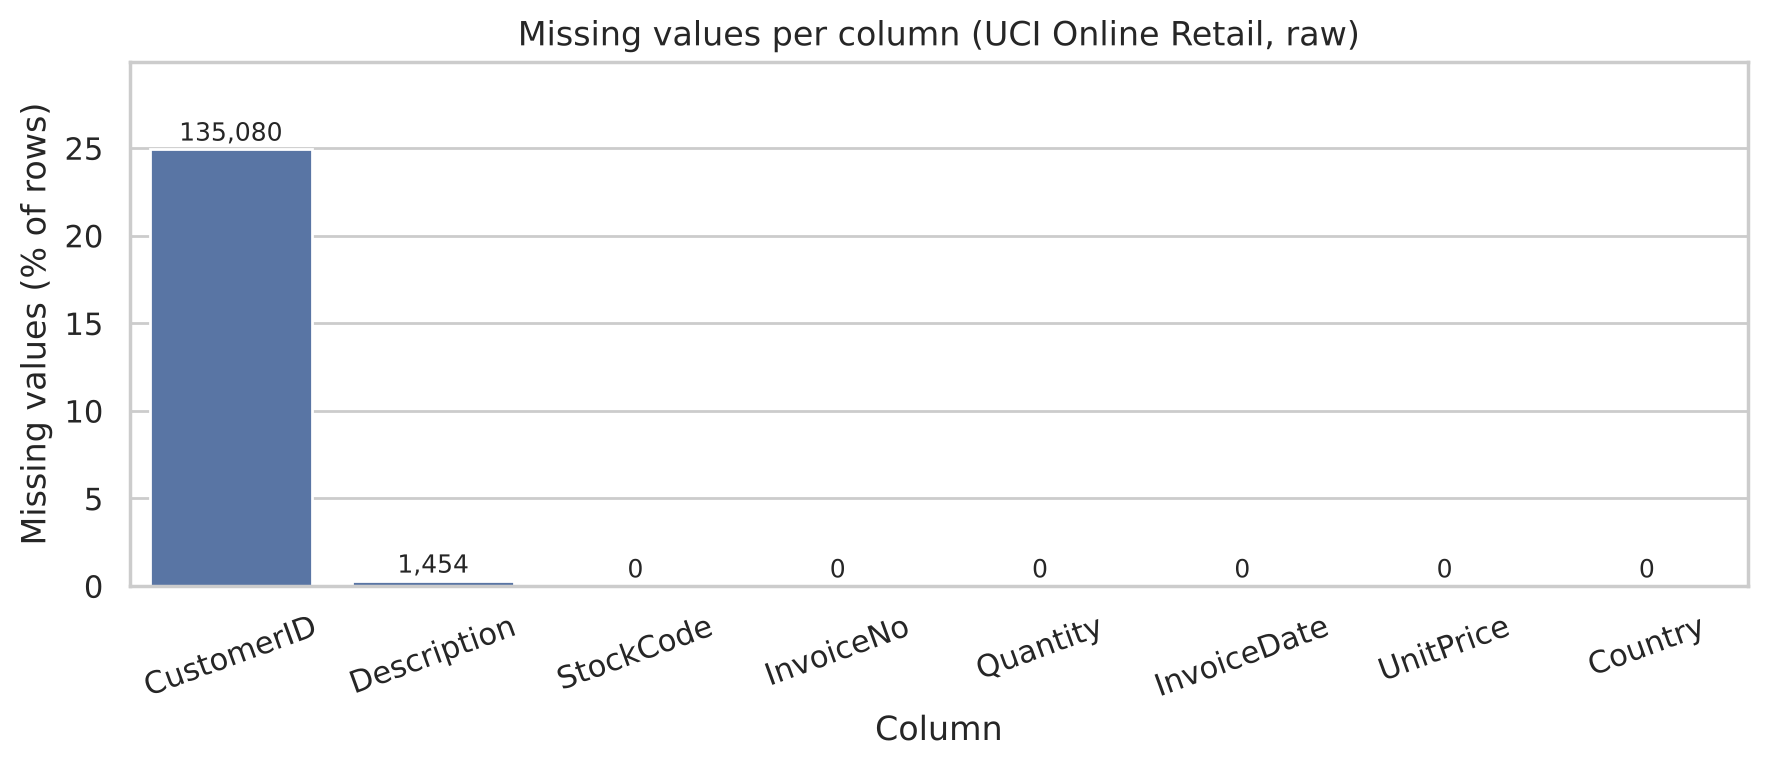

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
plot_df = missing.reset_index(names="column").sort_values("missing_pct", ascending=False)
sns.barplot(data=plot_df, x="column", y="missing_pct", color="#4C72B0", ax=ax)
for i, (pct, cnt) in enumerate(zip(plot_df["missing_pct"], plot_df["missing"])):
    ax.text(i, pct + 0.5, f"{cnt:,}", ha="center", fontsize=9)
ax.set_title("Missing values per column (UCI Online Retail, raw)")
ax.set_xlabel("Column")
ax.set_ylabel("Missing values (% of rows)")
ax.set_ylim(0, max(plot_df["missing_pct"].max() * 1.2, 1))
plt.xticks(rotation=20)
plt.tight_layout()
fig.savefig(config.FIGURES_DIR / "01_missing_values.png", dpi=150)
plt.show()

**Business interpretation:** missing `CustomerID` only affects *customer-level* analysis (who bought).
It does **not** affect *product demand* (what was bought, how much, when), so these rows stay useful for forecasting.
Missing `Description` rows are examined in Stage 3 together with their quantities and prices.

## 9. Duplicate analysis
An *exact duplicate* is a row identical to another row in **all 8 columns**.
`keep="first"` counts only the *extra* copies (the first occurrence is not counted as a duplicate).

In [15]:
extra_copies = df.duplicated(keep="first").sum()
involved = df.duplicated(keep=False).sum()
print(f"Extra duplicate rows        : {extra_copies:,} ({extra_copies / len(df):.2%})")
print(f"Rows involved in duplication: {involved:,}")
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6)

Extra duplicate rows        : 5,268 (0.97%)
Rows involved in duplication: 10,147


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom


## 10. Unique products, customers and invoices

In [16]:
is_cancel = df["InvoiceNo"].str.upper().str.startswith("C")
uniques = pd.Series({
    "Unique products (StockCode)": df["StockCode"].nunique(),
    "Unique descriptions": df["Description"].nunique(),
    "Unique customers (CustomerID)": df["CustomerID"].nunique(),
    "Unique invoices": df["InvoiceNo"].nunique(),
    "  of which cancelled (C...)": df.loc[is_cancel, "InvoiceNo"].nunique(),
    "Unique countries": df["Country"].nunique(),
}, name="count")
uniques.to_frame()

,count
Unique products (StockCode),4070
Unique descriptions,4211
Unique customers (CustomerID),4372
Unique invoices,25900
of which cancelled (C...),3836
Unique countries,38


## 11. Full overview report (saved for the dashboard and the PBL report)
The same checks are bundled into `profile_dataset()`, which also records early **data-quality observations**
(cancellations, negative quantities, zero/negative prices, non-product codes such as `POST` or `BANK CHARGES`)
and compares what we found with UCI's documentation. The report is saved as JSON (read by the FastAPI backend) and Markdown.

In [17]:
profile = profile_dataset(result)
paths = save_overview_report(profile)
print("Saved:", [p.name for p in paths.values()])

pd.Series({k: v for k, v in profile["quality_observations"].items() if isinstance(v, int)}, name="rows").to_frame()

Saved: ['01_dataset_overview.json', '01_dataset_overview.md']


,rows
cancellation_rows_invoice_starts_with_C,9288
negative_quantity_rows,10624
negative_quantity_rows_not_cancelled,1336
zero_quantity_rows,0
zero_unit_price_rows,2515
negative_unit_price_rows,2
missing_customer_id_rows,135080
missing_description_rows,1454
non_standard_stockcode_rows,2995
stockcodes_with_multiple_descriptions,647


In [18]:
check = profile["uci_documented_check"]
pd.DataFrame({
    "documented by UCI": check["documented"],
    "observed in file": check["observed"],
    "match": {"rows": check["rows_match"], "columns": check["columns_match"], "period": check["period_match"]},
})

,documented by UCI,observed in file,match
rows,541909,541909,True
columns,8,8,True
period,2010-12 to 2011-12,2010-12 to 2011-12,True


In [19]:
pd.Series(profile["quality_observations"]["non_standard_stockcode_examples"], name="rows").to_frame("rows (non-product StockCodes)")

,rows (non-product StockCodes)
POST,1256
DOT,710
M,571
C2,144
D,77
S,63
BANK CHARGES,37
AMAZONFEE,34
CRUK,16
DCGSSGIRL,13


## 12. Summary of what we learned

The printout below is generated from the data — re-running on a different file updates it automatically.

In [20]:
d, u, q, dr = profile["dimensions"], profile["unique_counts"], profile["quality_observations"], profile["date_range"]
print(f"""
- The file has {d['rows']:,} invoice lines and {d['columns']} columns, from {dr['min'][:10]} to {dr['max'][:10]}
  ({dr['distinct_transaction_days']} trading days in a {dr['span_days']}-day window — roughly one year, so we cannot claim yearly seasonality).
- {u['products_stockcode']:,} products, {u['customers']:,} identified customers, {u['invoices']:,} invoices, {u['countries']} countries.
- {q['missing_customer_id_rows']:,} rows ({q['missing_customer_id_rows']/d['rows']:.1%}) have no CustomerID -> fine for product demand, excluded only from customer analysis.
- {q['cancellation_rows_invoice_starts_with_C']:,} cancellation lines (invoice starts with 'C') and {q['negative_quantity_rows']:,} negative-quantity lines
  ({q['negative_quantity_rows_not_cancelled']:,} negative lines are NOT marked as cancellations -> likely stock adjustments; investigated in Stage 3).
- {q['zero_unit_price_rows']:,} zero-price and {q['negative_unit_price_rows']} negative-price lines -> excluded from revenue in Stage 3.
- {profile['duplicates']['exact_duplicate_rows']:,} exact duplicate rows.
- {q['non_standard_stockcode_rows']:,} lines use non-product codes (postage, fees, manual adjustments) -> not product demand.
- {q['stockcodes_with_multiple_descriptions']:,} StockCodes appear with more than one description -> descriptions will be standardised in Stage 3.
""")


- The file has 541,909 invoice lines and 8 columns, from 2010-12-01 to 2011-12-09
  (305 trading days in a 374-day window — roughly one year, so we cannot claim yearly seasonality).
- 4,070 products, 4,372 identified customers, 25,900 invoices, 38 countries.
- 135,080 rows (24.9%) have no CustomerID -> fine for product demand, excluded only from customer analysis.
- 9,288 cancellation lines (invoice starts with 'C') and 10,624 negative-quantity lines
  (1,336 negative lines are NOT marked as cancellations -> likely stock adjustments; investigated in Stage 3).
- 2,515 zero-price and 2 negative-price lines -> excluded from revenue in Stage 3.
- 5,268 exact duplicate rows.
- 2,995 lines use non-product codes (postage, fees, manual adjustments) -> not product demand.
- 647 StockCodes appear with more than one description -> descriptions will be standardised in Stage 3.



### Next stage
`02_exploratory_data_analysis.ipynb` — sales, product, customer, country and time patterns with charts and business interpretations.